# Sound Event Detection: Keyword Spotting with Classical DSP and Neural Networks

## Abstract
This project addresses *sound event detection*: locating a short, specific spoken word inside a
longer audio recording. A single recording of the target word is first analysed through its volume
(root-mean-square energy) and its spectrogram. The word is then recorded several times to build a
small dataset, and two compact neural networks are trained to distinguish the target word from other
sounds. The audio is processed with the `librosa` library, and the classification is carried out
with scikit-learn together with a small Keras convolutional network. The notebook also serves as the
written report: each step is preceded by a short explanation.

## Outline
1. Load one recording of the target word and display its waveform.
2. Plot the volume (RMS) over time and the spectrogram.
3. Build a small dataset from several recordings.
4. Slide the word across a longer recording and compare the volume (correlation plot).
5. Convert every sound into a low-resolution spectrogram.
6. Train a fully-connected network with scikit-learn (MLP).
7. Train a small three-layer CNN with Keras.
8. Compare the two models.

When the `data/` folder contains no recordings, the notebook generates a few simple synthetic sounds
so that it still runs from start to finish.

## Introduction

*Sound event detection* is the task of automatically finding when a particular sound occurs within
an audio signal. A familiar everyday example is keyword spotting, in which a device listens for a
single wake-word. In this project the chosen target is a short spoken word, and the goal is to detect
it both with a simple signal-comparison method and with trained neural networks.

Two complementary representations of a sound are used throughout this report:

- **Volume (RMS).** The *root-mean-square* energy of short, overlapping windows of the signal gives a
  simple measure of how loud the sound is at each instant. Plotted against time, it forms the volume
  envelope, which shows *where* energy is present but not *which* sound produced it.
- **Spectrogram.** The spectrogram shows how the signal's energy is distributed across frequency as
  time progresses. It is obtained from the short-time Fourier transform and reveals *which*
  frequencies are active, which is what makes it possible to tell different sounds (and words) apart.

Figure 1 (Section 1) illustrates both representations on one of my own recordings. The rest of the
report builds on them: the volume is used for a simple correlation-based search (Section 4), and
low-resolution spectrograms serve as the input to the classifiers (Sections 5 to 7).

## 0. Setup and imports

This section imports the required libraries: NumPy and Matplotlib for computation and plotting,
`librosa` for the audio processing, and scikit-learn for the machine learning. TensorFlow/Keras is
imported for the convolutional network; if it is not available, the notebook still runs and simply
skips the CNN section (tracked by the `HAS_TF` flag). The random seeds are fixed so that the results
are reproducible across runs.

In [1]:
# Basic scientific libraries
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt

# Audio
import librosa
import librosa.display
from scipy.io import wavfile   # to write/read the small synthetic .wav files

# Machine learning (scikit-learn)
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# --- Settings used throughout the notebook ------------------------------------
RANDOM_SEED = 42          # fixed seed so results stay the same
SR = 22050                # sample rate (Hz) for every clip
FRAME_LENGTH = 1024       # window length for the STFT / RMS (samples)
HOP_LENGTH = 256          # step between windows (samples)
CLIP_DURATION = 1.0       # length (s) every clip is padded/cut to
TOP_DB = 25               # how quiet counts as silence when splitting
MIN_EVENT_DUR = 0.10      # drop sounds shorter than this (s)
MAX_EVENT_DUR = 0.80      # split sounds longer than this (s)
MIN_GAP = 0.08            # merge sounds separated by a gap smaller than this (s)

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# --- Try to load TensorFlow/Keras for the CNN ---------------------------------
# scikit-learn has no CNN, so the CNN in Section 7 uses Keras. If TensorFlow is
# not installed, HAS_TF stays False and that section is simply skipped.
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    tf.random.set_seed(RANDOM_SEED)
    HAS_TF = True
    print(f"TensorFlow available (v{tf.__version__}) -> CNN section enabled.")
except Exception as exc:
    HAS_TF = False
    print("TensorFlow not available -> the CNN section will be skipped.")
    print("Reason:", exc)

# Show the plots inside the notebook.
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 4)

TensorFlow available (v2.21.0) -> CNN section enabled.


## 1. Loading the sound

A single recording of the target word is loaded first. `AUDIO_PATH` is set to the first `.wav` file
directly inside `data/`, so renaming the file does not break the path. If no file is present,
`make_synthetic_word()` generates a simple stand-in sound so that the rest of the notebook still
runs.

### 1.0 Generating data when the folder is empty

`ensure_synthetic_dataset()` inspects the `data/` folder. If real recordings are present, it leaves
them untouched and they are used as they are. If the folder is empty, it writes a few simple test
sounds with `scipy.io.wavfile`: a 440 Hz beep as the target, a recording in which that beep is
repeated several times in noise, and a recording containing other tones. This allows the notebook to
run on a computer where my own recordings are not available. The same `make_beep()` helper is reused
by the test in Section 4.2.

In [2]:
# --- Synthetic-audio building blocks (reused by the §4.2 validation) -----------
def make_beep(freq=440.0, dur=0.5, sr=SR, ramp=0.01):
    '''A pure `freq`-Hz tone of `dur` seconds with short raised-cosine fades.

    The fades remove the click that a hard on/off would add (which would smear
    energy across all frequencies and blur the spectrogram).
    '''
    n = int(sr * dur)
    t = np.linspace(0, dur, n, endpoint=False)
    sig = np.sin(2 * np.pi * freq * t).astype(np.float32)
    k = max(1, int(ramp * sr))                       # fade length in samples
    fade = (0.5 * (1 - np.cos(np.linspace(0, np.pi, k)))).astype(np.float32)
    sig[:k] *= fade
    sig[-k:] *= fade[::-1]
    return sig


def _to_int16(x):
    '''Peak-normalize a float signal to [-1, 1] and convert to 16-bit PCM.'''
    x = np.clip(x / (np.max(np.abs(x)) + 1e-9), -1.0, 1.0)
    return (x * 32767).astype(np.int16)


def embed_events(total_dur, events, noise=0.02, sr=SR, seed=0):
    '''White noise of `total_dur` s with each `(start_s, signal)` summed in.

    Returns `(y, start_times)` so callers know exactly where each event begins.
    '''
    rng = np.random.default_rng(seed)
    y = (noise * rng.standard_normal(int(sr * total_dur))).astype(np.float32)
    starts = []
    for start_s, sig in events:
        at = int(start_s * sr)
        end = min(len(y), at + len(sig))
        y[at:end] += sig[:end - at]
        starts.append(start_s)
    return y, starts


def ensure_synthetic_dataset():
    '''Write a known-answer 440 Hz dataset to data/ ONLY when no recordings exist.

    Non-destructive: if any real .wav is already present (root or class folders),
    the function leaves the data untouched and the rest of the notebook uses it.
    '''
    existing = glob.glob("data/**/*.wav", recursive=True)
    if existing:
        print(f"Found {len(existing)} real recording(s) in data/ "
              "-> using them (no synthetic data written).")
        return

    os.makedirs("data/positive", exist_ok=True)
    os.makedirs("data/negative", exist_ok=True)

    # Target template: one clean 440 Hz beep.
    wavfile.write("data/target.wav", SR, _to_int16(make_beep(440.0, 0.5)))

    # Positive: 440 Hz beeps embedded in white noise at known timestamps.
    pos, _ = embed_events(
        5.2, [(ts, make_beep(440.0, 0.4)) for ts in (0.6, 1.8, 3.0, 4.2)], seed=1
    )
    wavfile.write("data/positive/beeps_in_noise.wav", SR, _to_int16(pos))

    # Negative: DIFFERENT tones (not 440 Hz) in white noise.
    neg, _ = embed_events(
        5.2, [(0.6 + 1.2 * i, make_beep(f, 0.4))
              for i, f in enumerate((220.0, 880.0, 1500.0, 660.0))], seed=2
    )
    wavfile.write("data/negative/other_tones.wav", SR, _to_int16(neg))

    print("data/ was empty -> wrote a synthetic 440 Hz dataset "
          "(target.wav, positive/beeps_in_noise.wav, negative/other_tones.wav).")


ensure_synthetic_dataset()

Found 3 real recording(s) in data/ -> using them (no synthetic data written).


Loaded real recording: data\deneme_sound.wav  (2.75 s, 60682 samples)


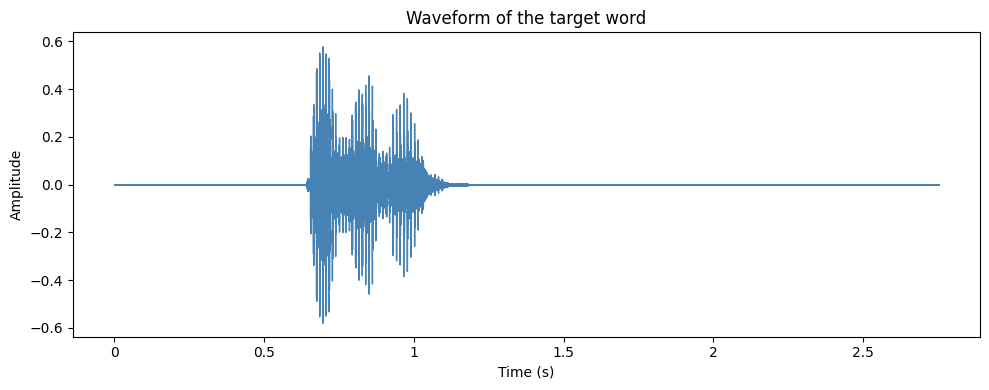

In [3]:
# Single example recording of the target word: the first .wav placed directly in data/.
# Auto-detected, so renaming the file never breaks this path.
_root_wavs = sorted(glob.glob("data/*.wav"))
AUDIO_PATH = _root_wavs[0] if _root_wavs else "data/target.wav"   # synthetic fallback if none


def make_synthetic_word(sr=SR, duration=CLIP_DURATION, seed=None):
    '''Generate a short synthetic two-syllable utterance (placeholder audio).

    The signal sums a few formant-like sine components, shapes them with a
    two-syllable amplitude envelope, and adds light noise. It only exists so the
    notebook is runnable without real recordings.
    '''
    rng = np.random.default_rng(seed)
    n = int(sr * duration)
    t = np.linspace(0, duration, n, endpoint=False)

    # Two amplitude bumps approximate two syllables.
    env = (np.exp(-((t - 0.25) ** 2) / (2 * 0.05 ** 2))
           + 0.9 * np.exp(-((t - 0.60) ** 2) / (2 * 0.06 ** 2)))

    # A slowly varying fundamental plus a few fixed "formant" frequencies (Hz).
    f0 = 140 + 20 * np.sin(2 * np.pi * 3 * t)
    formants = [f0, 700 + 0 * t, 1100 + 0 * t, 2600 + 0 * t]

    sig = np.zeros(n)
    for k, f in enumerate(formants):
        # cumsum(f)/sr integrates instantaneous frequency into phase.
        sig += (0.6 ** k) * np.sin(2 * np.pi * np.cumsum(f) / sr)

    sig = sig * env + 0.01 * rng.standard_normal(n)     # apply envelope + noise
    sig = sig / (np.max(np.abs(sig)) + 1e-9)            # normalize to [-1, 1]
    return sig.astype(np.float32)


def load_audio(path, sr=SR):
    '''Load a mono recording at the target sample rate, or fall back to synthetic.'''
    if path and os.path.isfile(path):
        y, _ = librosa.load(path, sr=sr, mono=True)
        print(f"Loaded real recording: {path}  ({len(y) / sr:.2f} s, {len(y)} samples)")
    else:
        y = make_synthetic_word(sr=sr, seed=0)
        print(f"No file at '{path}' -> using a synthetic target signal "
              f"({len(y) / sr:.2f} s).")
    return y


# Load the example clip and visualize its waveform.
y = load_audio(AUDIO_PATH)

plt.figure()
librosa.display.waveshow(y, sr=SR, color="steelblue")
plt.title("Waveform of the target word")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

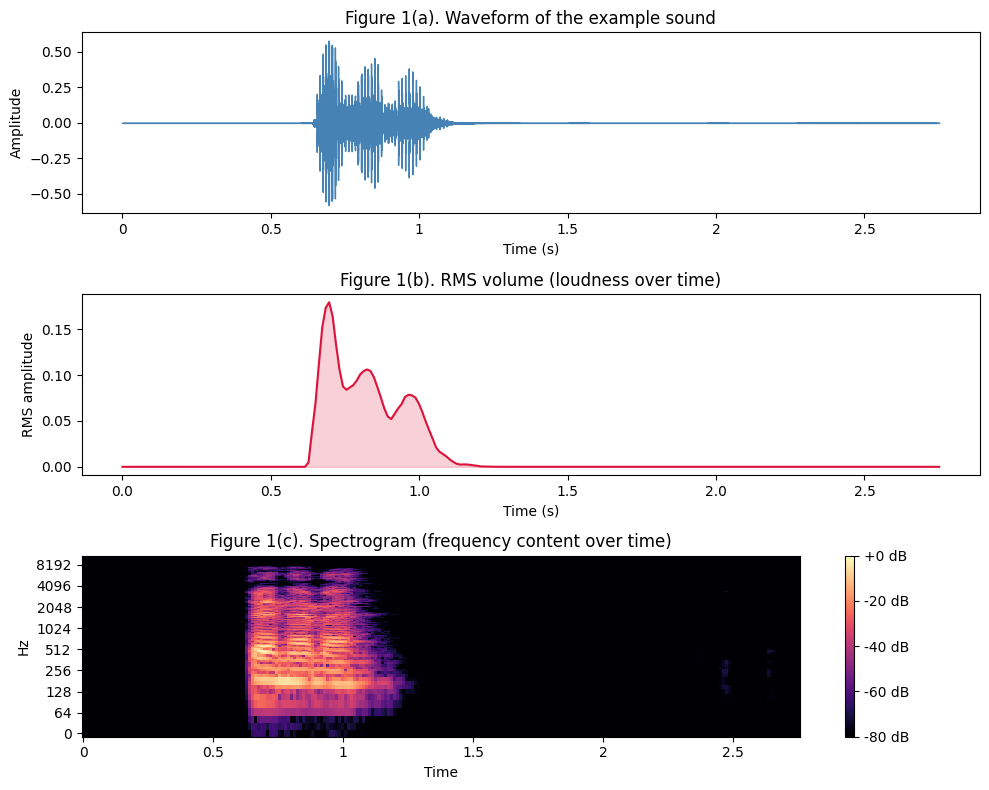

In [4]:
# Figure 1: the two representations used throughout the report, computed from the
# example recording loaded above -- its waveform, its RMS volume (loudness over time),
# and its spectrogram (energy across frequency over time).
fig, ax = plt.subplots(3, 1, figsize=(10, 8))

# (a) Waveform: the raw signal amplitude over time.
librosa.display.waveshow(y, sr=SR, color="steelblue", ax=ax[0])
ax[0].set_title("Figure 1(a). Waveform of the example sound")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")

# (b) RMS volume: how loud the sound is at each moment.
intro_rms = librosa.feature.rms(y=y, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH)[0]
intro_times = librosa.frames_to_time(np.arange(len(intro_rms)), sr=SR, hop_length=HOP_LENGTH)
ax[1].plot(intro_times, intro_rms, color="crimson")
ax[1].fill_between(intro_times, intro_rms, alpha=0.2, color="crimson")
ax[1].set_title("Figure 1(b). RMS volume (loudness over time)")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("RMS amplitude")

# (c) Spectrogram: which frequencies are present, and how strong, over time.
intro_db = librosa.amplitude_to_db(
    np.abs(librosa.stft(y, n_fft=FRAME_LENGTH, hop_length=HOP_LENGTH)), ref=np.max
)
intro_img = librosa.display.specshow(
    intro_db, sr=SR, hop_length=HOP_LENGTH, x_axis="time", y_axis="log", cmap="magma", ax=ax[2]
)
ax[2].set_title("Figure 1(c). Spectrogram (frequency content over time)")
fig.colorbar(intro_img, ax=ax[2], format="%+2.0f dB")

plt.tight_layout()
plt.show()

## 2. Analysing the sound

### 2.1 Volume over time (RMS)
The *root-mean-square* (RMS) value of short, overlapping windows of the signal is a simple measure of
how loud the sound is at each moment. It is computed with `librosa.feature.rms`, and the frame
indices are converted to seconds with `librosa.frames_to_time` so that the horizontal axis is in real
time.

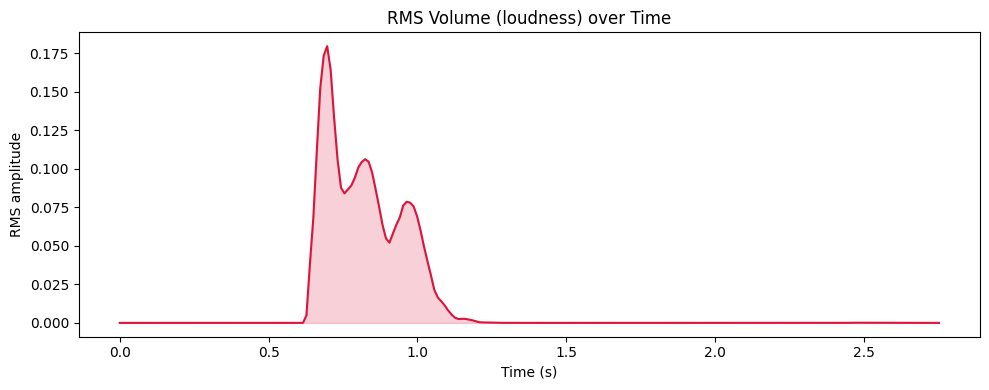

In [5]:
# Compute frame-wise RMS energy (loudness envelope).
rms = librosa.feature.rms(
    y=y, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH
)[0]

# Map each RMS frame to its time position (seconds).
rms_times = librosa.frames_to_time(
    np.arange(len(rms)), sr=SR, hop_length=HOP_LENGTH
)

plt.figure()
plt.plot(rms_times, rms, color="crimson")
plt.fill_between(rms_times, rms, alpha=0.2, color="crimson")
plt.title("RMS Volume (loudness) over Time")
plt.xlabel("Time (s)")
plt.ylabel("RMS amplitude")
plt.tight_layout()
plt.show()

### 2.2 Spectrogram
The spectrogram shows which frequencies are present over time. The short-time Fourier transform is
computed with `librosa.stft`, converted to decibels, and displayed on a logarithmic frequency axis,
which is closer to the way the human ear perceives pitch.

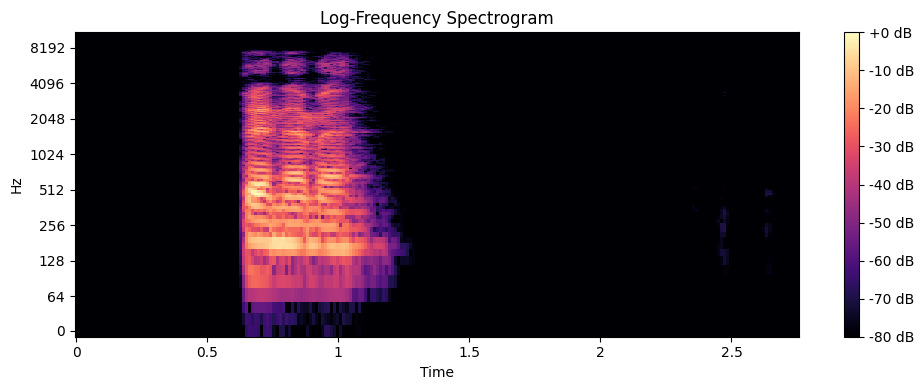

In [6]:
# Short-Time Fourier Transform -> magnitude -> decibel scale.
S = np.abs(librosa.stft(y, n_fft=FRAME_LENGTH, hop_length=HOP_LENGTH))
S_db = librosa.amplitude_to_db(S, ref=np.max)

plt.figure()
img = librosa.display.specshow(
    S_db, sr=SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="log", cmap="magma",
)
plt.colorbar(img, format="%+2.0f dB")
plt.title("Log-Frequency Spectrogram")
plt.tight_layout()
plt.show()

## 3. Building the dataset

For training, all recordings in two folders are used:

- `data/positive/` for recordings that contain the target word (label 1),
- `data/negative/` for other sounds, such as counting or different words (label 0).

Each recording usually contains several sounds, so instead of treating a whole file as one clip, it
is split into separate sounds with `librosa.effects.split`, which cuts on the silent parts. The
result is then cleaned up: pieces that are very close together are merged, pieces that are too long
(most likely two sounds joined together) are split, and pieces that are too short to be a real sound
are discarded. The two classes usually contain a different number of sounds, so they are balanced by
keeping an equal number from each. Because the number of examples is still small, light augmentation
is added (a small amount of noise, a small time shift, and a change in volume). Finally, every clip
is padded or trimmed to the same length.

In [7]:
# Folders of class recordings. Every .wav inside is read and segmented into events.
POSITIVE_DIR = "data/positive"   # recordings that CONTAIN the target word
NEGATIVE_DIR = "data/negative"   # recordings that do NOT contain the target word


def make_negative_sound(sr=SR, duration=CLIP_DURATION, seed=None):
    '''Generate a synthetic non-target sound: a random tone, noise burst, or chirp.'''
    rng = np.random.default_rng(seed)
    n = int(sr * duration)
    t = np.linspace(0, duration, n, endpoint=False)
    kind = int(rng.integers(0, 3))
    if kind == 0:                                   # steady random-pitch tone
        sig = np.sin(2 * np.pi * rng.uniform(200, 3000) * t)
    elif kind == 1:                                 # broadband noise burst
        sig = rng.standard_normal(n)
    else:                                           # frequency up-chirp
        f0, f1 = rng.uniform(200, 500), rng.uniform(2000, 4000)
        sig = np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t ** 2 / (2 * duration)))
    env = np.exp(-((t - duration / 2) ** 2) / (2 * 0.15 ** 2))
    sig = sig * env + 0.01 * rng.standard_normal(n)
    sig = sig / (np.max(np.abs(sig)) + 1e-9)
    return sig.astype(np.float32)


def fix_length(sig, sr=SR, dur=CLIP_DURATION):
    '''Pad with zeros or trim a signal to exactly `dur` seconds.'''
    return librosa.util.fix_length(sig, size=int(sr * dur))


def segment_intervals(y, sr=SR, top_db=TOP_DB):
    '''Split a loaded signal into `(start, end)` sample ranges, one per sound event.

    Sensitivity tuning so each spoken sound is captured exactly once, whether the
    sounds are closely-spaced (alphabet letters) or have brief internal dips:
      1. split on silence using the shared FINE analysis window (`FRAME_LENGTH` /
         `HOP_LENGTH`) instead of librosa's coarse default, which otherwise smooths
         over the short gaps between fast sounds and merges them;
      2. **merge** pieces separated by a gap smaller than `MIN_GAP` (a single sound
         that briefly dips in energy and was therefore over-split);
      3. **re-split** any event longer than `MAX_EVENT_DUR` at its quietest interior
         point (two sounds merged across a shallow gap);
      4. **drop** fragments shorter than `MIN_EVENT_DUR` (background clicks, not speech).

    Returning the index ranges (rather than the audio) lets the correlation step
    reuse the exact same event boundaries as the dataset builder.
    '''
    intervals = librosa.effects.split(
        y, top_db=top_db, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH
    )

    # 2. Merge intervals separated by a tiny gap (over-split of a single sound).
    min_gap = int(MIN_GAP * sr)
    merged = []
    for start, end in intervals:
        if merged and start - merged[-1][1] < min_gap:
            merged[-1] = (merged[-1][0], end)
        else:
            merged.append((int(start), int(end)))

    # 3. Re-split any interval that is suspiciously long (two merged sounds).
    refined = []
    for start, end in merged:
        if (end - start) / sr <= MAX_EVENT_DUR:
            refined.append((start, end))
            continue
        env = librosa.feature.rms(
            y=y[start:end], frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH
        )[0]
        if len(env) < 4:
            refined.append((start, end))
            continue
        margin = len(env) // 6                       # ignore the edges when seeking the valley
        cut = start + (margin + int(np.argmin(env[margin:len(env) - margin]))) * HOP_LENGTH
        refined.append((start, cut))
        refined.append((cut, end))

    # 4. Keep only events long enough to be a genuine spoken sound.
    return [(s, e) for s, e in refined if (e - s) / sr >= MIN_EVENT_DUR]


def segment_events(path, sr=SR, top_db=TOP_DB):
    '''Load a recording and split it into individual non-silent sound-event clips.'''
    y, _ = librosa.load(path, sr=sr, mono=True)
    return [y[s:e] for s, e in segment_intervals(y, sr=sr, top_db=top_db)]


def collect_events(folder, top_db=TOP_DB):
    '''Segment every .wav in `folder` into events and pool them into one list.'''
    events = []
    for path in sorted(glob.glob(os.path.join(folder, "*.wav"))):
        clip_events = segment_events(path, top_db=top_db)
        print(f"  {os.path.basename(path):<22}-> {len(clip_events):>2} events")
        events.extend(clip_events)
    return events


def augment_clip(clip, seed=None):
    '''Return several variants of a clip: original, +noise, time-shifted, re-gained.'''
    rng = np.random.default_rng(seed)
    noisy = clip + 0.005 * rng.standard_normal(len(clip)).astype(np.float32)
    shifted = np.roll(clip, int(rng.integers(1, max(2, len(clip) // 4))))
    gained = (clip * rng.uniform(0.7, 1.3)).astype(np.float32)
    return [clip, noisy, shifted, gained]


# --- Low-resolution mel-spectrogram feature (shared by §4 detection and §5 models) ---
LOWRES_SHAPE = (32, 32)   # (mel bins, time steps) after downsampling


def _resize2d(arr, out_shape):
    '''Resize a 2-D array to `out_shape` using 1-D linear interpolation per axis.'''
    in_r, in_c = arr.shape
    out_r, out_c = out_shape

    # Interpolate along columns (time) first.
    col_idx = np.linspace(0, in_c - 1, out_c)
    tmp = np.empty((in_r, out_c))
    src_c = np.arange(in_c)
    for r in range(in_r):
        tmp[r] = np.interp(col_idx, src_c, arr[r])

    # Then interpolate along rows (frequency).
    row_idx = np.linspace(0, in_r - 1, out_r)
    out = np.empty((out_r, out_c))
    src_r = np.arange(in_r)
    for c in range(out_c):
        out[:, c] = np.interp(row_idx, src_r, tmp[:, c])
    return out


def extract_lowres_spectrogram(sig, sr=SR, out_shape=LOWRES_SHAPE, n_mels=64):
    '''Mel-spectrogram (dB) downsampled to a small fixed grid, normalized to [0, 1].

    Captures the *frequency content* of a clip (unlike the volume envelope), so it
    is used both to identify the target word in §4 and as the model input in §5.
    A short or silent clip is zero-padded to one analysis window so librosa always
    returns at least one frame, and a final `nan_to_num` guarantees the result is
    finite before it ever reaches a model.
    '''
    # Guard against clips shorter than one analysis window (avoids empty STFT frames).
    if len(sig) < FRAME_LENGTH:
        sig = librosa.util.fix_length(sig, size=FRAME_LENGTH)
    mel = librosa.feature.melspectrogram(
        y=sig, sr=sr, n_mels=n_mels, hop_length=HOP_LENGTH
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = _resize2d(mel_db, out_shape)
    img = (img - img.min()) / (np.ptp(img) + 1e-9)
    # Safety net: a silent/degenerate clip must never inject NaN/Inf into the model.
    img = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)
    return img.astype(np.float32)

With the helper functions in place, the labelled dataset is built. If the folders are empty, a
synthetic set is generated instead so that the notebook still runs.

In [8]:
def build_dataset(augment=True, balance=True):
    '''Build (clips, labels, groups) from the recordings in the two class folders.

    Every .wav in the positive/negative folders is cut into separate sounds and
    collected per class. The classes are balanced, and each sound is expanded with a
    little augmentation. If the folders are empty (or give too few sounds), a
    synthetic set is generated instead so that the notebook still runs.

    `groups` stores, for each clip, the id of the sound it came from. All augmented
    copies of one sound share the same group id. This is later used to keep copies of
    the same sound out of both the train and the test set.
    '''
    pos_files = glob.glob(os.path.join(POSITIVE_DIR, "*.wav"))
    neg_files = glob.glob(os.path.join(NEGATIVE_DIR, "*.wav"))

    pos_events, neg_events = [], []
    if pos_files and neg_files:
        print("Positive recordings:")
        pos_events = collect_events(POSITIVE_DIR)
        print("Negative recordings:")
        neg_events = collect_events(NEGATIVE_DIR)

    # At least 2 sounds per class are needed for the split; otherwise synthesize data.
    if len(pos_events) >= 2 and len(neg_events) >= 2:
        # Balance the two classes by keeping the same number of sounds from each.
        if balance:
            rng = np.random.default_rng(RANDOM_SEED)
            k = min(len(pos_events), len(neg_events))
            if len(pos_events) > k:
                keep = sorted(rng.choice(len(pos_events), k, replace=False))
                pos_events = [pos_events[i] for i in keep]
            if len(neg_events) > k:
                keep = sorted(rng.choice(len(neg_events), k, replace=False))
                neg_events = [neg_events[i] for i in keep]
            print(f"Balanced to {k} events per class.")

        clips, labels, groups = [], [], []
        group_id = 0
        for label, events in [(1, pos_events), (0, neg_events)]:
            for i, event in enumerate(events):
                variants = augment_clip(event, seed=label * 1000 + i) if augment else [event]
                for v in variants:
                    clips.append(fix_length(v))
                    labels.append(label)
                    groups.append(group_id)   # all copies of one sound share a group
                group_id += 1
    else:
        if pos_files and neg_files:
            print("Too few events segmented from the folders "
                  f"(positive={len(pos_events)}, negative={len(neg_events)}) "
                  "-> synthesizing a balanced dataset.")
        else:
            print("Class folders empty -> synthesizing a balanced dataset.")
        clips, labels, groups = [], [], []
        for i in range(40):
            clips.append(make_synthetic_word(seed=1000 + i)); labels.append(1); groups.append(2 * i)
            clips.append(make_negative_sound(seed=2000 + i)); labels.append(0); groups.append(2 * i + 1)

    return clips, np.array(labels, dtype=int), np.array(groups, dtype=int)


audio_clips, labels, groups = build_dataset(augment=True)
print(f"\nDataset size: {len(audio_clips)} clips | "
      f"positives: {int(labels.sum())} | negatives: {int((labels == 0).sum())} | "
      f"source-event groups: {len(np.unique(groups))}")

Positive recordings:


  multiple_deneme_sounds.wav->  9 events
Negative recordings:
  multiple_test_sounds.wav->  9 events
Balanced to 9 events per class.

Dataset size: 72 clips | positives: 36 | negatives: 36 | source-event groups: 18


## 4. Finding the word in a longer recording

A simple, model-free way to search for a word is template matching: the RMS volume of the target
word is slid across the RMS volume of a longer recording, and the resulting match at each position is
plotted as a correlation curve.

Volume alone, however, only indicates *where* the loud parts are, not *which* word produced them:
every spoken sound has a similar loud-then-quiet shape, so the volume of one word matches almost any
other word. To decide whether a given sound is the target word, its frequency content is compared
instead. For each sound in the long recording, the procedure is:

1. cut the recording into separate sounds (the same splitter as before),
2. compare each sound to the target word using MFCC features, which describe the "colour" of a sound
   rather than its loudness, and
3. count the sound as a match when this similarity reaches `SPECTRAL_THRESHOLD` (0.88).

A simpler low-resolution mel-spectrogram comparison was tried first, but it produced high scores
(around 0.6 to 0.8) for almost any two voiced sounds, so a different word could exceed the threshold
by accident. MFCCs separate the same word (about 0.95 to 1.0) from a different word (below 0.85) far
more clearly. The volume correlation curve is still shown for comparison, but the final count is
based on the MFCC comparison.

In [9]:
# Minimum similarity for a sound to count as a match with the target word. The score
# is the cosine similarity of the MFCC features (the "colour" of the sound, not its
# loudness), so a different word receives a low score and is rejected. The value 0.88
# was chosen because the same word scores about 0.95-1.0 and a different word stays
# below 0.85.
SPECTRAL_THRESHOLD = 0.88


def rms_envelope(sig):
    '''RMS volume of the signal, frame by frame.'''
    return librosa.feature.rms(
        y=sig, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH
    )[0]


def sliding_xcorr(signal_env, template_env):
    '''Slide the template volume over the longer volume and measure the match.

    Returns an empty array if the template is longer than the signal, so the caller
    does not crash. This is only used to draw the volume correlation curve.
    '''
    template = template_env - template_env.mean()
    t_norm = np.linalg.norm(template) + 1e-9
    out = np.zeros(max(0, len(signal_env) - len(template_env) + 1))
    for i in range(len(out)):
        seg = signal_env[i:i + len(template_env)] - signal_env[i:i + len(template_env)].mean()
        out[i] = np.dot(seg, template) / (np.linalg.norm(seg) * t_norm + 1e-9)
    return out


def _mfcc_descriptor(sig, n_mfcc=20):
    '''One MFCC vector per clip (the average of its MFCCs over time).

    MFCCs describe the shape of the frequency content, which indicates which sound it
    is. The first coefficient (overall energy) is dropped so that loudness does not
    matter, the coefficients are averaged over time to obtain one vector, and the mean
    is removed before comparison.
    '''
    if len(sig) < FRAME_LENGTH:
        sig = librosa.util.fix_length(sig, size=FRAME_LENGTH)
    mfcc = librosa.feature.mfcc(y=sig, sr=SR, n_mfcc=n_mfcc, hop_length=HOP_LENGTH)[1:]
    v = mfcc.mean(axis=1)
    v = v - v.mean()
    return np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0)


def spectral_similarity(clip_a, clip_b):
    '''How similar two clips sound: cosine similarity of their MFCC vectors.

    This compares the frequency content, not the loudness, so the same word scores
    high (about 0.95-1.0) and a different word scores low (below 0.85). That is what
    lets the detector decide that a sound is not the target word.
    '''
    va = _mfcc_descriptor(clip_a)
    vb = _mfcc_descriptor(clip_b)
    return float(np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb) + 1e-9))


def pick_template(path):
    '''Return one clean clip of the target word to use as the template.

    The longest sound in the recording is taken. If nothing was found (a very short
    file) the whole clip is used, and if the file is missing a synthetic word is used
    so that this step never crashes.
    '''
    if path and os.path.isfile(path):
        events = segment_events(path)
        if events:
            return max(events, key=len)
        y, _ = librosa.load(path, sr=SR, mono=True)
        if len(y):
            return y
    return make_synthetic_word(seed=0)


def detect_occurrences(long_y, template_clip, threshold=SPECTRAL_THRESHOLD):
    '''Count how many times the template appears in the long recording.

    1. cut the recording into separate sounds,
    2. compare each sound to the template with `spectral_similarity` (MFCC), and
    3. count a sound as a match when the score reaches `threshold`.
    Returns (events, scores, detected): the (start, end) of each sound, its score,
    and a True/False mask of which ones matched.
    '''
    events = segment_intervals(long_y)
    scores = np.array([
        spectral_similarity(template_clip, long_y[start:end]) for start, end in events
    ])
    detected = scores >= threshold
    return events, scores, detected


# Pick the template (the target word) and the longer recording to search in.
pos_files = sorted(glob.glob(os.path.join(POSITIVE_DIR, "*.wav")))
LONG_RECORDING = pos_files[0] if pos_files else None

if os.path.isfile(AUDIO_PATH) and LONG_RECORDING:
    template_clip = pick_template(AUDIO_PATH)
    long_y, _ = librosa.load(LONG_RECORDING, sr=SR, mono=True)
    print(f"Searching for the '{os.path.basename(AUDIO_PATH)}' template "
          f"inside '{os.path.basename(LONG_RECORDING)}'.")
else:
    # If the files are missing, build a synthetic long recording with 3 words in it.
    template_clip = make_synthetic_word(seed=0)
    rng = np.random.default_rng(7)
    long_y = 0.02 * rng.standard_normal(int(SR * 6.0)).astype(np.float32)
    for k in range(3):
        at = int((1.2 + 1.6 * k) * SR)
        long_y[at:at + len(template_clip)] += template_clip
    print("Source files missing -> using a synthetic long recording.")

# Volume correlation curve (shown for comparison in the plot below).
long_env = rms_envelope(long_y)
template_env = rms_envelope(template_clip)
corr = sliding_xcorr(long_env, template_env)
corr_times = librosa.frames_to_time(np.arange(len(corr)), sr=SR, hop_length=HOP_LENGTH)

# MFCC-based detection (this is what actually gives the count).
events, event_scores, detected = detect_occurrences(long_y, template_clip)
print(f"Detected {int(detected.sum())} occurrence(s) of the target word "
      f"({len(events)} sound event(s), MFCC timbre similarity >= {SPECTRAL_THRESHOLD:.2f}).")

Searching for the 'deneme_sound.wav' template inside 'multiple_deneme_sounds.wav'.
Detected 9 occurrence(s) of the target word (9 sound event(s), MFCC timbre similarity >= 0.88).


The plot below shows the long recording's volume (RMS) together with the correlation curve and the
detected peaks.

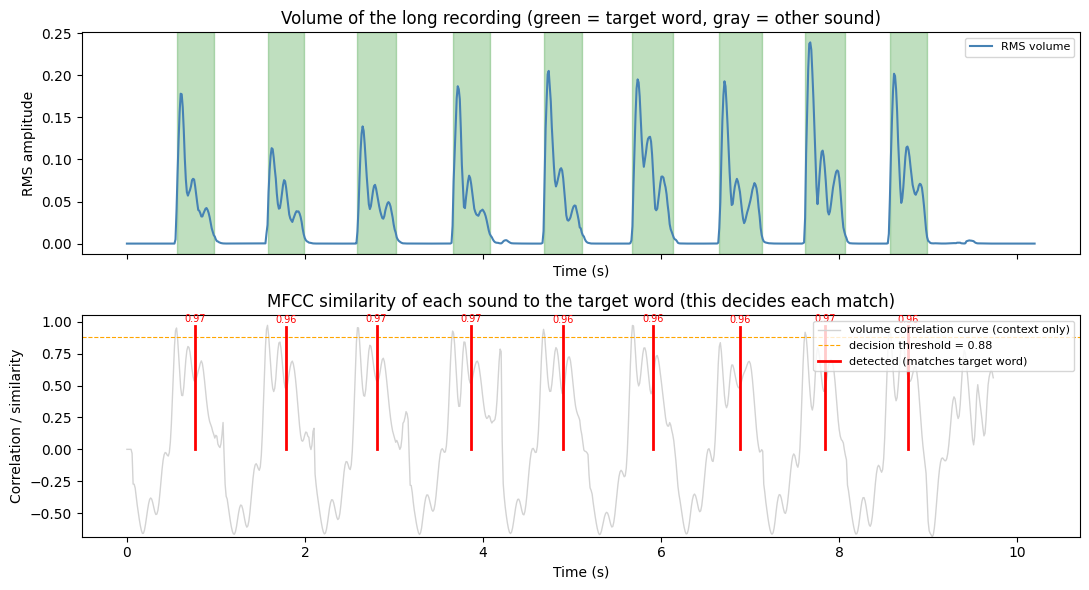

In [10]:
long_times = librosa.frames_to_time(np.arange(len(long_env)), sr=SR, hop_length=HOP_LENGTH)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Top plot: the volume of the long recording. Each sound is shaded green if it matched
# the target word and gray if it did not.
ax[0].plot(long_times, long_env, color="steelblue", label="RMS volume")
for (start, end), is_hit in zip(events, detected):
    ax[0].axvspan(start / SR, end / SR, color="green" if is_hit else "gray",
                  alpha=0.25 if is_hit else 0.12)
ax[0].set_title("Volume of the long recording (green = target word, gray = other sound)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("RMS amplitude")
ax[0].legend(loc="upper right", fontsize=8)

# Bottom plot: two different things.
#   * gray line  = the volume correlation curve (the "compare the volume" plot). It
#     is just context and does NOT decide anything.
#   * red/gray bars = the MFCC similarity of each sound, which is what is compared
#     to the threshold.
ax[1].plot(corr_times, corr, color="lightgray", lw=1,
           label="volume correlation curve (context only)")
ax[1].axhline(SPECTRAL_THRESHOLD, color="orange", ls="--", lw=0.8,
              label=f"decision threshold = {SPECTRAL_THRESHOLD:.2f}")
shown = {True: False, False: False}
for (start, end), score, is_hit in zip(events, event_scores, detected):
    center = (start + end) / 2 / SR
    color = "red" if is_hit else "dimgray"
    ax[1].plot([center, center], [0, score], color=color, lw=2,
               label=("detected (matches target word)" if is_hit else "rejected (different sound)")
               if not shown[bool(is_hit)] else None)
    shown[bool(is_hit)] = True
    ax[1].text(center, min(1.0, score + 0.03), f"{score:.2f}",
               ha="center", fontsize=7, color=color)
ax[1].set_title("MFCC similarity of each sound to the target word (this decides each match)")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Correlation / similarity")
ax[1].set_ylim(min(-0.1, float(np.min(corr)) if len(corr) else -0.1), 1.05)
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### 4.1 Testing the detector on known sounds

Because the real example files change frequently, the detector is also tested on self-generated
sounds for which the correct answer is known by construction. Recordings containing exactly 1, 3, 5
and 8 copies of the target word are built, and two properties are checked: the target template should
find exactly that many, and a different sound should find none of them. The `assert` statements stop
the notebook if either property fails.

In [11]:
# Self-test: build recordings whose contents are KNOWN, then check the detector.
# Two properties are asserted, so the notebook fails loudly if either regresses:
#   (1) a TARGET-word template finds exactly the right number of target words;
#   (2) a DIFFERENT-sound template finds NONE of them (no false positives).
def make_known_recording(n_words, gap=0.6, lead=0.5, word_dur=0.5, noise=0.01, seed=0,
                         maker=make_synthetic_word):
    '''Concatenate `n_words` synthetic words (from `maker`) separated by silent gaps.'''
    rng = np.random.default_rng(seed)
    parts = [rng.standard_normal(int(SR * lead)).astype(np.float32) * noise]
    for i in range(n_words):
        parts.append(maker(seed=1000 + i, duration=word_dur))
        parts.append(rng.standard_normal(int(SR * gap)).astype(np.float32) * noise)
    return np.concatenate(parts)


target_template = make_synthetic_word(seed=0, duration=0.5)        # the target word
different_template = make_negative_sound(seed=7, duration=0.5)     # a DIFFERENT sound

print(f"{'recording':>22} | {'template':>10} | {'expected':>8} | {'detected':>8} | result")
print("-" * 70)
all_ok = True
for true_count in [1, 3, 5, 8]:
    rec = make_known_recording(true_count, seed=true_count)        # rec of TARGET words
    # (1) correct template -> should find exactly `true_count`.
    _, _, det_same = detect_occurrences(rec, target_template)
    ok_same = int(det_same.sum()) == true_count
    # (2) different template -> should find 0 (the sound is not there).
    _, _, det_diff = detect_occurrences(rec, different_template)
    ok_diff = int(det_diff.sum()) == 0
    all_ok = all_ok and ok_same and ok_diff
    print(f"{f'{true_count} target words':>22} | {'target':>10} | {true_count:>8} | "
          f"{int(det_same.sum()):>8} | {'PASS' if ok_same else 'FAIL'}")
    print(f"{'':>22} | {'different':>10} | {0:>8} | "
          f"{int(det_diff.sum()):>8} | {'PASS' if ok_diff else 'FAIL'}")

assert all_ok, "Self-test failed: detector miscounted or matched the wrong sound."
print("\nAll self-tests passed -> right count for the target word, zero for a different sound.")

             recording |   template | expected | detected | result
----------------------------------------------------------------------
        1 target words |     target |        1 |        1 | PASS
                       |  different |        0 |        0 | PASS
        3 target words |     target |        3 |        3 | PASS
                       |  different |        0 |        0 | PASS
        5 target words |     target |        5 |        5 | PASS
                       |  different |        0 |        0 | PASS


        8 target words |     target |        8 |        8 | PASS
                       |  different |        0 |        0 | PASS

All self-tests passed -> right count for the target word, zero for a different sound.


### 4.2 Testing the whole pipeline on a 440 Hz beep

Section 4.1 checks only the counting. Here every stage of the pipeline is tested on a recording built
from 440 Hz beeps placed in noise at known times, so the expected behaviour at each stage is known in
advance:

1. the RMS volume should rise at the beep times,
2. the spectrogram should show energy around 440 Hz,
3. the volume correlation should peak at a beep,
4. the detector should find exactly the beeps and nothing for a different tone, and
5. a small network trained on beeps versus other tones should label a new beep correctly.

Each property is verified with an `assert`. The small network used here is independent of the main
models in Sections 6 and 7.

In [12]:
# Build a KNOWN beep-in-noise recording: 440 Hz beeps at fixed start times.
BEEP_STARTS = [0.6, 1.8, 3.0, 4.2]            # seconds (ground truth)
BEEP_DUR = 0.4
val_rec, _ = embed_events(
    5.2, [(s, make_beep(440.0, BEEP_DUR)) for s in BEEP_STARTS], noise=0.02, seed=11
)
beep_centers = np.array([s + BEEP_DUR / 2 for s in BEEP_STARTS])
checks = []

# (1) RMS volume spikes AT the insertion times (and nowhere else).
v_rms = rms_envelope(val_rec)
v_times = librosa.frames_to_time(np.arange(len(v_rms)), sr=SR, hop_length=HOP_LENGTH)
background = np.median(v_rms)
at_beeps = all(v_rms[np.abs(v_times - c) < 0.15].max() > 4 * background for c in beep_centers)
loud_times = v_times[v_rms > 0.5 * v_rms.max()]
no_spurious = all(np.min(np.abs(beep_centers - t)) < 0.25 for t in loud_times)
checks.append(("RMS volume spikes at the beep timestamps", at_beeps and no_spurious))

# (2) Spectrogram energy peaks at 440 Hz during a beep.
seg = val_rec[int((beep_centers[0] - 0.15) * SR):int((beep_centers[0] + 0.15) * SR)]
spectrum = np.abs(librosa.stft(seg, n_fft=FRAME_LENGTH, hop_length=HOP_LENGTH)).mean(axis=1)
fft_freqs = librosa.fft_frequencies(sr=SR, n_fft=FRAME_LENGTH)
peak_freq = float(fft_freqs[int(np.argmax(spectrum))])
checks.append((f"Spectrogram peaks at 440 Hz (measured {peak_freq:.0f} Hz)",
               abs(peak_freq - 440.0) < 40))

# (3) Sliding VOLUME correlation peaks at a beep location.
corr_v = sliding_xcorr(rms_envelope(val_rec), rms_envelope(make_beep(440.0, BEEP_DUR)))
corr_t = librosa.frames_to_time(np.arange(len(corr_v)), sr=SR, hop_length=HOP_LENGTH)
peak_time = float(corr_t[int(np.argmax(corr_v))]) if len(corr_v) else -1.0
checks.append((f"Volume correlation peaks at a beep (t = {peak_time:.2f} s)",
               len(corr_v) > 0 and min(abs(np.array(BEEP_STARTS) - peak_time)) < 0.25))

# (4) Spectral detector: exactly the embedded beeps, and 0 for a DIFFERENT tone.
_, _, det_same = detect_occurrences(val_rec, make_beep(440.0, BEEP_DUR))
_, _, det_diff = detect_occurrences(val_rec, make_beep(1500.0, BEEP_DUR))
checks.append((f"Detector finds {int(det_same.sum())} beeps (expected {len(BEEP_STARTS)})",
               int(det_same.sum()) == len(BEEP_STARTS)))
checks.append((f"Detector finds {int(det_diff.sum())} for a different tone (expected 0)",
               int(det_diff.sum()) == 0))

# (5) A small NN trained on synthetic beeps vs other tones classifies FRESH clips.
def _noisy_clip(freq, seed):
    r = np.random.default_rng(seed)
    sig = make_beep(freq, BEEP_DUR) + 0.02 * r.standard_normal(int(SR * BEEP_DUR)).astype(np.float32)
    return fix_length(sig)

other_freqs = [220.0, 880.0, 1500.0, 660.0]
Xv, yv = [], []
for i in range(20):
    Xv.append(extract_lowres_spectrogram(_noisy_clip(440.0, i))); yv.append(1)
    Xv.append(extract_lowres_spectrogram(_noisy_clip(other_freqs[i % 4], 100 + i))); yv.append(0)
Xv = np.stack(Xv).reshape(len(Xv), -1)
assert np.isfinite(Xv).all(), "Non-finite features in the synthetic NN validation set."
v_scaler = StandardScaler().fit(Xv)
v_mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600,
                      random_state=RANDOM_SEED).fit(v_scaler.transform(Xv), np.array(yv))
fresh_beep = v_scaler.transform(extract_lowres_spectrogram(_noisy_clip(440.0, 999)).reshape(1, -1))
fresh_other = v_scaler.transform(extract_lowres_spectrogram(_noisy_clip(880.0, 998)).reshape(1, -1))
nn_ok = int(v_mlp.predict(fresh_beep)[0]) == 1 and int(v_mlp.predict(fresh_other)[0]) == 0
checks.append(("NN: fresh beep -> target, fresh other tone -> non-target", nn_ok))

# Report and hard-assert every stage.
print(f"{'pipeline stage check':<52} | result")
print("-" * 64)
for name, ok in checks:
    print(f"{name:<52} | {'PASS' if ok else 'FAIL'}")
assert all(ok for _, ok in checks), "Synthetic 440 Hz end-to-end validation FAILED."
print("\nAll synthetic 440 Hz pipeline stages validated (RMS, spectrogram, correlation, "
      "detector, NN).")

pipeline stage check                                 | result
----------------------------------------------------------------
RMS volume spikes at the beep timestamps             | PASS
Spectrogram peaks at 440 Hz (measured 431 Hz)        | PASS
Volume correlation peaks at a beep (t = 1.80 s)      | PASS
Detector finds 4 beeps (expected 4)                  | PASS
Detector finds 0 for a different tone (expected 0)   | PASS
NN: fresh beep -> target, fresh other tone -> non-target | PASS

All synthetic 440 Hz pipeline stages validated (RMS, spectrogram, correlation, detector, NN).


## 5. Low-resolution spectrograms as features

A full-resolution spectrogram is large, which would make the network large as well. To keep it small,
each clip is converted into a mel-spectrogram in decibels and reduced to a fixed 32x32 grid with
simple linear interpolation. Each feature map is then scaled to the range 0 to 1.

Feature tensor X: (72, 32, 32) | labels: (72,) | finite & shape-checked OK


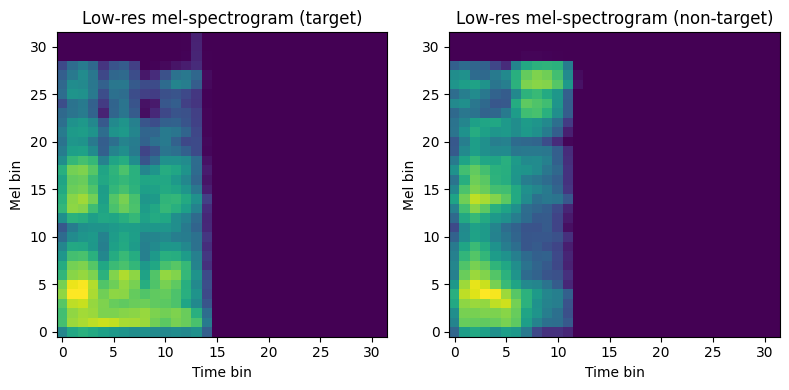

In [13]:
# extract_lowres_spectrogram and LOWRES_SHAPE are defined once in the helpers cell of
# Section 3, so the detector and the models use the same feature.

# Build the feature array X (N, 32, 32) and the labels.
X = np.stack([extract_lowres_spectrogram(clip) for clip in audio_clips])
y_labels = labels

# A few quick checks before training, just to be safe.
assert X.shape[1:] == LOWRES_SHAPE, f"Feature grid {X.shape[1:]} != LOWRES_SHAPE {LOWRES_SHAPE}"
assert np.isfinite(X).all(), "Found NaN/Inf values in X."
assert X.shape[0] == len(y_labels) == len(groups), "X / labels / groups length mismatch."
print(f"Feature tensor X: {X.shape} | labels: {y_labels.shape} | finite & shape-checked OK")

# Show one positive and one negative example next to each other.
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, target_label, ttl in [(ax[0], 1, "target"), (ax[1], 0, "non-target")]:
    matches = np.flatnonzero(y_labels == target_label)
    if matches.size:
        a.imshow(X[matches[0]], origin="lower", aspect="auto", cmap="viridis")
        a.set_title(f"Low-res mel-spectrogram ({ttl})")
    else:
        a.set_title(f"(no {ttl} example available)")
    a.set_xlabel("Time bin"); a.set_ylabel("Mel bin")
plt.tight_layout()
plt.show()

## 6. Model A: scikit-learn MLP

This section builds a small fully-connected network with scikit-learn. scikit-learn does
not provide convolution layers, only the `MLPClassifier` (an ordinary fully-connected network), so it
is used here on the flattened spectrograms, while a true convolutional network is built with Keras in
Section 7. The data is divided once into training, validation and test sets, shared by both models so
that the comparison is fair, and the features are standardised with the scaler fitted on the training
data only.

Train: 40 clips | Validation: 16 clips | Test: 16 clips | groups disjoint across all three sets.


MLP validation accuracy: 1.000
MLP test accuracy:       1.000

              precision    recall  f1-score   support

  non-target       1.00      1.00      1.00         8
      target       1.00      1.00      1.00         8

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



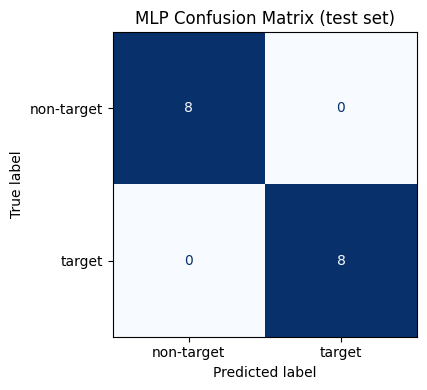

In [14]:
# The data is split once into training, validation and test sets, shared by both
# models so that the comparison is fair. The split is group-aware: all augmented
# copies of one source sound stay on the same side. A purely random split could place
# copies of the same sound in different sets, which would make the scores look better
# than they really are.
#
# StratifiedGroupKFold is applied twice: first to hold out a test set, then to split
# the remainder into training and validation. Both splits keep the classes balanced
# and never share a source-event group between sets.
gkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
idx_rest, idx_test = next(gkf_test.split(X, y_labels, groups))          # ~20% test

gkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)
rel_train, rel_val = next(gkf_val.split(X[idx_rest], y_labels[idx_rest], groups[idx_rest]))
idx_train, idx_val = idx_rest[rel_train], idx_rest[rel_val]            # ~60% / ~20%

y_train, y_val, y_test = y_labels[idx_train], y_labels[idx_val], y_labels[idx_test]

# Check that the three sets share no source-event group and each holds both classes.
g_tr, g_va, g_te = set(groups[idx_train]), set(groups[idx_val]), set(groups[idx_test])
assert g_tr.isdisjoint(g_va) and g_tr.isdisjoint(g_te) and g_va.isdisjoint(g_te), \
    "A source-event group appears in more than one split."
assert set(y_train) == {0, 1} and set(y_val) == {0, 1} and set(y_test) == {0, 1}, \
    "A class is missing from one of the splits."
print(f"Train: {len(idx_train)} clips | Validation: {len(idx_val)} clips | "
      f"Test: {len(idx_test)} clips | groups disjoint across all three sets.")

# Flatten the spectrograms into vectors and standardize them (scaler fitted on train only).
X_flat = X.reshape(X.shape[0], -1)
assert X_flat.shape[1] == LOWRES_SHAPE[0] * LOWRES_SHAPE[1], "Flattened width != mel grid size."
scaler = StandardScaler().fit(X_flat[idx_train])
X_train_mlp = scaler.transform(X_flat[idx_train])
X_val_mlp = scaler.transform(X_flat[idx_val])
X_test_mlp = scaler.transform(X_flat[idx_test])

# A fully-connected network with 3 hidden layers.
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    max_iter=800,
    random_state=RANDOM_SEED,
)
mlp.fit(X_train_mlp, y_train)

# Validation accuracy (used to judge the model) and the final test accuracy.
mlp_val_acc = accuracy_score(y_val, mlp.predict(X_val_mlp))
mlp_pred = mlp.predict(X_test_mlp)
mlp_acc = accuracy_score(y_test, mlp_pred)
print(f"MLP validation accuracy: {mlp_val_acc:.3f}")
print(f"MLP test accuracy:       {mlp_acc:.3f}\n")
print(classification_report(y_test, mlp_pred, target_names=["non-target", "target"]))

# Confusion matrix on the test set.
cm = confusion_matrix(y_test, mlp_pred)
ConfusionMatrixDisplay(cm, display_labels=["non-target", "target"]).plot(
    cmap="Blues", colorbar=False
)
plt.title("MLP Confusion Matrix (test set)")
plt.tight_layout()
plt.show()

## 7. Model B: a three-layer CNN with Keras

A convolutional network can exploit the two-dimensional structure of the spectrogram (local patterns
in time and frequency) that the flattened MLP discards. The network used here consists of three
convolutional blocks (Conv2D followed by MaxPooling) and a small dense head, trained with the Adam
optimiser and the binary cross-entropy loss. This is the three-layer CNN used for comparison,
and it runs only when TensorFlow is installed.

The data is divided into three parts: a **training** set used
to fit the weights, a **validation** set used during training to monitor over-fitting and to choose
hyper-parameters, and a held-out **test** set used only at the end to estimate the performance. The
training curves below therefore compare the training set against the separate validation set. The
training metrics may appear slightly worse than the validation metrics; this is expected here,
because dropout is active during training (which lowers the apparent training accuracy) but is
switched off during evaluation.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,129 (219.25 KB)

 Trainable params: 56,129 (219.25 KB)

 Non-trainable params: 0 (0.00 B)


CNN test accuracy: 1.000


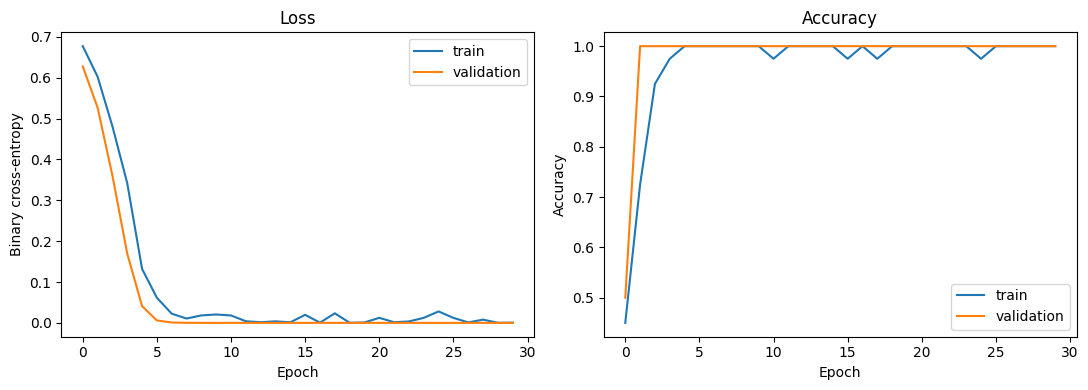

In [15]:
cnn_acc = None   # stays None if TensorFlow is not available

if not HAS_TF:
    print("TensorFlow is not installed -> skipping the CNN section.")
else:
    # Add a channel dimension: (N, 32, 32) -> (N, 32, 32, 1).
    Xc = X[..., np.newaxis]
    # Quick check that the shape matches what the CNN input expects.
    assert Xc.shape[1:] == (LOWRES_SHAPE[0], LOWRES_SHAPE[1], 1), \
        f"CNN input {Xc.shape[1:]} != expected {(LOWRES_SHAPE[0], LOWRES_SHAPE[1], 1)}"
    Xc_train, Xc_val, Xc_test = Xc[idx_train], Xc[idx_val], Xc[idx_test]

    # Three Conv2D + MaxPooling blocks, then a small dense head.
    model = keras.Sequential([
        keras.Input(shape=(LOWRES_SHAPE[0], LOWRES_SHAPE[1], 1)),
        layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),   # one output: probability of "target"
    ])

    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    model.summary()

    # Train on the training set and watch the separate validation set each epoch.
    history = model.fit(
        Xc_train, y_train,
        validation_data=(Xc_val, y_val),
        epochs=30, batch_size=8, verbose=0,
    )

    # Final performance is measured once, on the held-out test set.
    _, cnn_acc = model.evaluate(Xc_test, y_test, verbose=0)
    print(f"\nCNN test accuracy: {cnn_acc:.3f}")

    # Training curves: training set vs the separate validation set.
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history.history["loss"], label="train")
    ax[0].plot(history.history["val_loss"], label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Binary cross-entropy")
    ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="train")
    ax[1].plot(history.history["val_accuracy"], label="validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
    ax[1].legend()
    plt.tight_layout()
    plt.show()

## 8. Comparing the models

Finally, the two models are compared on the same held-out test set.

Test-set accuracy
----------------------------
  MLP (sklearn)   : 1.000
  CNN (Keras)     : 1.000


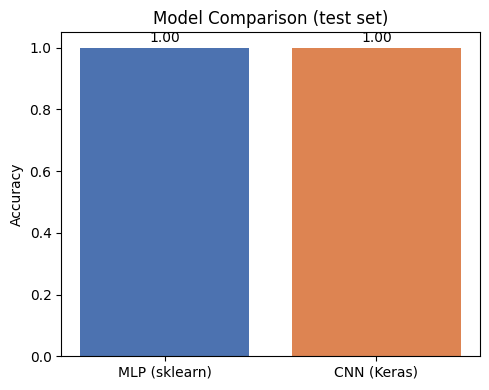

In [16]:
# Collect available results.
model_names, model_accs = ["MLP (sklearn)"], [mlp_acc]
if cnn_acc is not None:
    model_names.append("CNN (Keras)")
    model_accs.append(cnn_acc)

print("Test-set accuracy")
print("-" * 28)
for name, acc in zip(model_names, model_accs):
    print(f"  {name:<16}: {acc:.3f}")

plt.figure(figsize=(5, 4))
bars = plt.bar(model_names, model_accs, color=["#4C72B0", "#DD8452"][:len(model_names)])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Model Comparison (test set)")
for b, acc in zip(bars, model_accs):
    plt.text(b.get_x() + b.get_width() / 2, acc + 0.02, f"{acc:.2f}", ha="center")
plt.tight_layout()
plt.show()

### Notes and limitations
- The dataset is small (a few short recordings split into separate sounds, balanced, and lightly
  augmented), so the reported accuracy is likely optimistic. Collecting more, and more varied,
  recordings would give a more reliable estimate.
- The MLP treats the spectrogram as a flat vector, whereas the CNN uses its two-dimensional
  structure, which is usually advantageous for this kind of data.
- The volume-based template matching is fast and easy to interpret, but it is sensitive to loudness
  and timing; it is therefore used alongside the trained models rather than as a replacement for
  them.

## References and Acknowledgments

**AI tools.** I used an AI assistant (Anthropic's Claude) during this project to help write and
debug parts of the code, and reviewed the resulting code so that I can explain each step.

**Tutorial.** Jon Nordby, "Sound Event Detection with Machine Learning", used as a general
introduction to the sound-event-detection workflow.

**Libraries and their documentation.**
- librosa (audio loading and analysis): https://librosa.org/
- scikit-learn (MLPClassifier, scaling, metrics, data splitting): https://scikit-learn.org/
- TensorFlow / Keras (the three-layer CNN): https://www.tensorflow.org/
- NumPy: https://numpy.org/ ; SciPy: https://scipy.org/ ; Matplotlib: https://matplotlib.org/

The specific librosa functions used (from the documentation above) include `librosa.load`,
`librosa.feature.rms`, `librosa.stft`, `librosa.feature.melspectrogram`, `librosa.feature.mfcc`,
`librosa.effects.split`, and `librosa.frames_to_time`.